<a href="https://colab.research.google.com/github/hisyam270810/01092025/blob/main/Laporan_%26_Dashboard_Analisis_Data_Penjualan_(e_commerce).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama Kelompok 5 :
-Dafi Alfarezel Rachman / 08
-Muhammad Hisyam Darmawan / 30
-Dynand Fahreza Fauzy / 12
-Deniza Nabiel Akbar Al Fatih /10

In [2]:
# ============================================================
# SEL 1 - IMPORT LIBRARY
# Tujuan: memanggil semua library yang dibutuhkan sebelum analisis
# ============================================================
import pandas as pd              # untuk mengolah data berbentuk tabel (DataFrame)
import numpy as np               # untuk perhitungan numerik
import matplotlib.pyplot as plt  # untuk membuat grafik dasar
import seaborn as sns            # untuk grafik statistik yang lebih rapi (boxplot, dll)

In [4]:
# ============================================================
# SEL 2 - MEMUAT DATASET
# Tujuan: membaca file CSV ke dalam DataFrame bernama df
# ============================================================
df = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')  # sesuaikan path ke folder /content/

df.head()  # tampilkan 5 baris pertama untuk melihat gambaran isi data

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [5]:
# ============================================================
# SEL 3 - EKSPLORASI DATA
# Tujuan: memahami ukuran data, tipe kolom, data kosong, dan duplikat
# ============================================================
print("Ukuran data (baris, kolom):", df.shape)  # jumlah baris dan kolom

df.info()  # tipe data tiap kolom dan jumlah data yang terisi

print("\nJumlah data kosong per kolom:")
print(df.isnull().sum())  # menghitung nilai kosong (NaN) di setiap kolom

print("\nJumlah data duplikat:", df.duplicated().sum())  # baris yang sama persis

Ukuran data (baris, kolom): (4340, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Jumlah data kosong per kolom:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Jumlah data duplikat: 763


In [6]:
# ============================================================
# SEL 4 - PEMBERSIHAN DATA & PEMBUATAN FITUR BARU
# Tujuan: membuang duplikat dan menambah kolom yang berguna untuk analisis
# ============================================================
# Hapus baris duplikat agar penjualan tidak terhitung ganda
df = df.drop_duplicates().reset_index(drop=True)

# Ambil kata pertama dari nama mobil sebagai merek (contoh: "Maruti Swift" -> "Maruti")
df['brand'] = df['name'].str.split().str[0]

# Hitung umur mobil (tahun sekarang dikurangi tahun produksi)
df['umur_mobil'] = 2026 - df['year']

# Ubah harga ke satuan juta agar angkanya lebih mudah dibaca
df['harga_juta'] = df['selling_price'] / 1_000_000

# Ringkasan statistik awal: count, mean, std, min, kuartil, max
df.describe()

,year,selling_price,km_driven,umur_mobil,harga_juta
count,3577.000000,3.577000e+03,3577.000000,3577.000000,3577.000000
mean,2012.962538,4.739125e+05,69250.545709,13.037462,0.473913
std,4.251759,5.093018e+05,47579.940016,4.251759,0.509302
min,1992.000000,2.000000e+04,1.000000,6.000000,0.020000
25%,2010.000000,2.000000e+05,36000.000000,10.000000,0.200000
50%,2013.000000,3.500000e+05,60000.000000,13.000000,0.350000
75%,2016.000000,6.000000e+05,90000.000000,16.000000,0.600000
max,2020.000000,8.900000e+06,806599.000000,34.000000,8.900000


In [7]:
# ============================================================
# SEL 5 - STATISTIK DESKRIPTIF KUNCI
# Tujuan: menghitung angka ringkasan yang menjawab pertanyaan bisnis
# ============================================================
total_penjualan = df['selling_price'].sum()      # total nilai seluruh mobil terjual
rata_harga      = df['selling_price'].mean()     # rata-rata harga per transaksi
median_harga    = df['selling_price'].median()   # nilai tengah harga (tidak terpengaruh outlier)
brand_terlaris  = df['brand'].value_counts().idxmax()   # merek dengan unit terbanyak
jumlah_terlaris = df['brand'].value_counts().max()      # jumlah unit merek tersebut
bahan_bakar_top = df['fuel'].value_counts().idxmax()    # jenis bahan bakar terbanyak
rata_km         = df['km_driven'].mean()                # rata-rata kilometer tempuh
brand_termahal  = df.groupby('brand')['selling_price'].mean().idxmax()  # merek dengan rata-rata harga tertinggi

# Tampilkan semua hasil dengan format rapi (pemisah ribuan)
print(f"1. Total nilai penjualan : {total_penjualan:,.0f}")
print(f"2. Rata-rata harga       : {rata_harga:,.0f}")
print(f"3. Median harga          : {median_harga:,.0f}")
print(f"4. Brand terlaris        : {brand_terlaris} ({jumlah_terlaris} unit)")
print(f"5. Bahan bakar terbanyak : {bahan_bakar_top}")
print(f"6. Rata-rata km          : {rata_km:,.0f}")
print(f"7. Brand harga tertinggi : {brand_termahal}")

# Catatan untuk presentasi: jika rata-rata jauh di atas median,
# berarti ada mobil mahal yang menarik rata-rata ke atas.

1. Total nilai penjualan : 1,695,185,163
2. Rata-rata harga       : 473,913
3. Median harga          : 350,000
4. Brand terlaris        : Maruti (1072 unit)
5. Bahan bakar terbanyak : Diesel
6. Rata-rata km          : 69,251
7. Brand harga tertinggi : Land


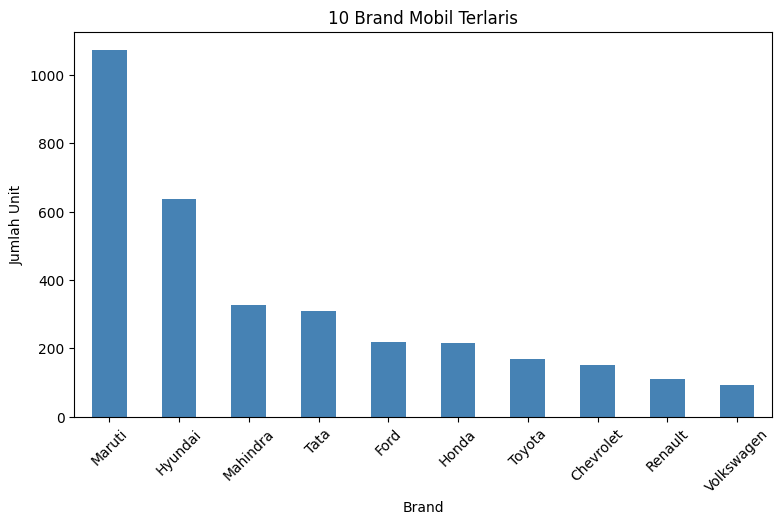

In [8]:
# ============================================================
# SEL 6 - GRAFIK 1: BAR CHART
# Pertanyaan bisnis: merek apa yang paling banyak terjual?
# ============================================================
plt.figure(figsize=(9, 5))                                  # atur ukuran gambar
df['brand'].value_counts().head(10).plot(kind='bar', color='steelblue')  # 10 merek terbanyak
plt.title('10 Brand Mobil Terlaris')                        # judul grafik
plt.xlabel('Brand')                                         # label sumbu X
plt.ylabel('Jumlah Unit')                                   # label sumbu Y
plt.xticks(rotation=45)                                     # miringkan nama merek agar terbaca
plt.show()                                                  # tampilkan grafik

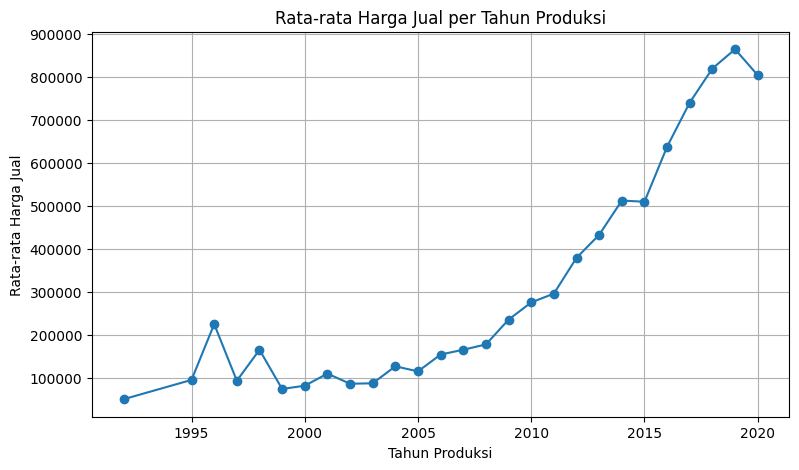

In [9]:
# ============================================================
# SEL 7 - GRAFIK 2: LINE CHART
# Pertanyaan bisnis: bagaimana tren harga berdasarkan tahun produksi?
# ============================================================
plt.figure(figsize=(9, 5))
df.groupby('year')['selling_price'].mean().plot(marker='o')  # rata-rata harga per tahun, titik ditandai
plt.title('Rata-rata Harga Jual per Tahun Produksi')
plt.xlabel('Tahun Produksi')
plt.ylabel('Rata-rata Harga Jual')
plt.grid(True)                                               # tambah garis bantu agar mudah dibaca
plt.show()


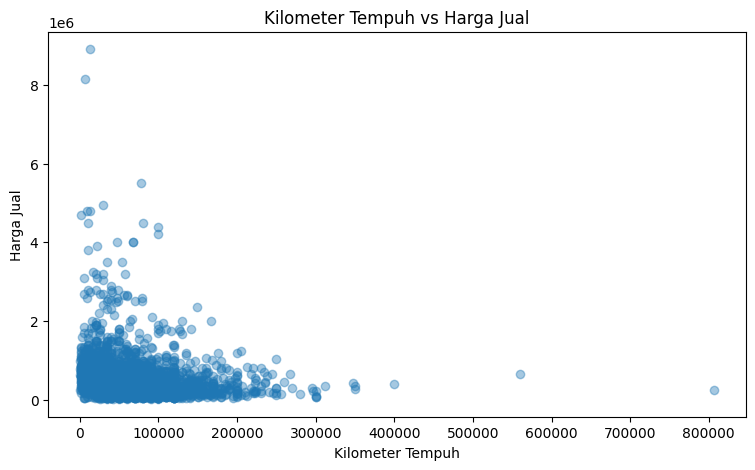

In [10]:
# ============================================================
# SEL 8 - GRAFIK 3: SCATTER PLOT
# Pertanyaan bisnis: apakah kilometer tempuh memengaruhi harga?
# ============================================================
plt.figure(figsize=(9, 5))
plt.scatter(df['km_driven'], df['selling_price'], alpha=0.4)  # alpha = transparansi agar titik yang menumpuk terlihat
plt.title('Kilometer Tempuh vs Harga Jual')
plt.xlabel('Kilometer Tempuh')
plt.ylabel('Harga Jual')
plt.show()

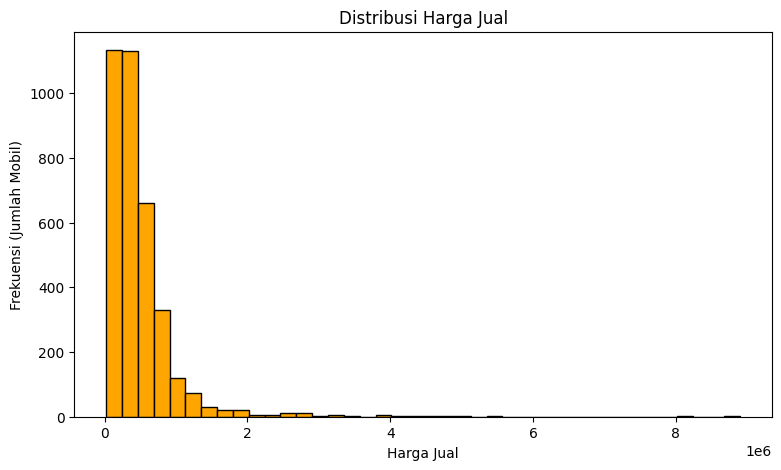

In [11]:
# ============================================================
# SEL 9 - GRAFIK 4: HISTOGRAM
# Pertanyaan bisnis: harga mobil paling banyak berada di rentang berapa?
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(df['selling_price'], bins=40, color='orange', edgecolor='black')  # bins = jumlah batang
plt.title('Distribusi Harga Jual')
plt.xlabel('Harga Jual')
plt.ylabel('Frekuensi (Jumlah Mobil)')
plt.show()

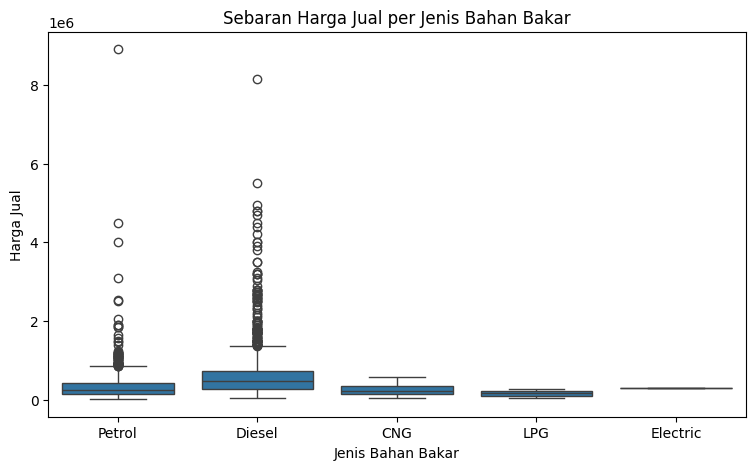

In [12]:
# ============================================================
# SEL 10 - GRAFIK 5: BOXPLOT
# Pertanyaan bisnis: bagaimana sebaran harga di tiap jenis bahan bakar?
# ============================================================
plt.figure(figsize=(9, 5))
sns.boxplot(x='fuel', y='selling_price', data=df)  # kotak = sebaran tengah, titik di luar = potensi outlier
plt.title('Sebaran Harga Jual per Jenis Bahan Bakar')
plt.xlabel('Jenis Bahan Bakar')
plt.ylabel('Harga Jual')
plt.show()

In [13]:
# ============================================================
# SEL 11 - DETEKSI OUTLIER DENGAN ATURAN IQR
# Tujuan: menemukan mobil dengan harga yang sangat menyimpang dari mayoritas
# Rumus: outlier = nilai di luar [Q1 - 1.5*IQR , Q3 + 1.5*IQR]
# ============================================================
Q1  = df['selling_price'].quantile(0.25)   # kuartil 1 (25% data berada di bawahnya)
Q3  = df['selling_price'].quantile(0.75)   # kuartil 3 (75% data berada di bawahnya)
IQR = Q3 - Q1                              # rentang antar kuartil (sebaran data tengah)

batas_bawah = Q1 - 1.5 * IQR               # batas bawah wajar
batas_atas  = Q3 + 1.5 * IQR               # batas atas wajar

# Ambil baris yang harganya di luar batas wajar
outlier = df[(df['selling_price'] < batas_bawah) | (df['selling_price'] > batas_atas)]

print(f"Batas bawah   : {batas_bawah:,.0f}")
print(f"Batas atas    : {batas_atas:,.0f}")
print(f"Jumlah outlier: {len(outlier)} dari {len(df)} mobil")

# Tampilkan 10 outlier dengan harga tertinggi untuk dianalisis penyebabnya
# (cek merek, tahun, dan kilometer: biasanya mobil premium atau berumur sangat muda)
outlier.sort_values('selling_price', ascending=False).head(10)

Batas bawah   : -400,000
Batas atas    : 1,200,000
Jumlah outlier: 170 dari 3577 mobil


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,umur_mobil,harga_juta
3257,Audi RS7 2015-2019 Sportback Performance,2016,8900000,13000,Petrol,Dealer,Automatic,First Owner,Audi,10,8.90
76,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500,Diesel,Dealer,Automatic,First Owner,Mercedes-Benz,9,8.15
3341,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350,Diesel,Dealer,Automatic,First Owner,Mercedes-Benz,10,5.50
540,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner,BMW,7,4.95
2881,BMW 5 Series 520d Luxury Line,2018,4800000,9422,Diesel,Individual,Automatic,First Owner,BMW,8,4.80
3267,BMW 5 Series 520d Luxury Line,2019,4800000,12999,Diesel,Dealer,Automatic,First Owner,BMW,7,4.80
846,Audi A5 Sportback,2020,4700000,1500,Diesel,Individual,Automatic,First Owner,Audi,6,4.70
88,Mercedes-Benz E-Class Exclusive E 200 BSIV,2018,4500000,9800,Petrol,Dealer,Automatic,First Owner,Mercedes-Benz,8,4.50
3385,Volvo XC 90 D5 Inscription BSIV,2017,4500000,80000,Diesel,Individual,Automatic,First Owner,Volvo,9,4.50
524,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,2014,4400000,100000,Diesel,Individual,Automatic,Second Owner,Mercedes-Benz,12,4.40


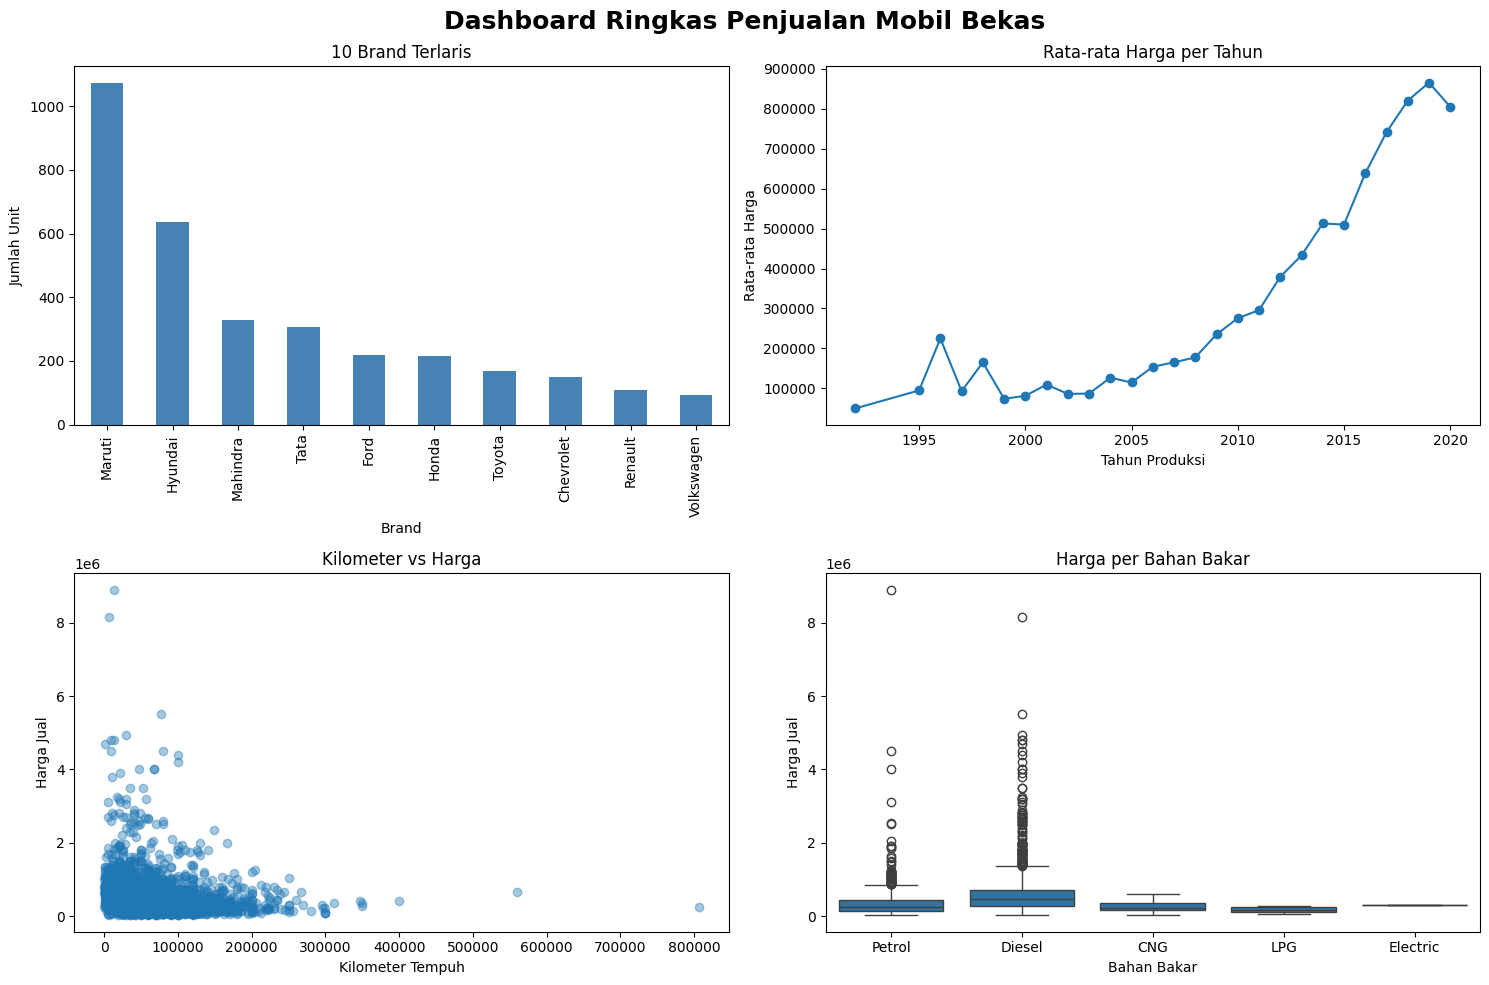

In [14]:
# ============================================================
# SEL 12 - DASHBOARD RINGKAS (4 GRAFIK DALAM 1 FIGURE)
# Tujuan: merangkum temuan utama dalam satu tampilan untuk manajemen
# ============================================================
# Buat kanvas 2 baris x 2 kolom; axes adalah "petak" tempat tiap grafik diletakkan
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Dashboard Ringkas Penjualan Mobil Bekas', fontsize=18, fontweight='bold')

# Petak kiri-atas: Bar chart merek terlaris
df['brand'].value_counts().head(10).plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('10 Brand Terlaris')
axes[0, 0].set_xlabel('Brand')
axes[0, 0].set_ylabel('Jumlah Unit')

# Petak kanan-atas: Line chart tren harga per tahun
df.groupby('year')['selling_price'].mean().plot(marker='o', ax=axes[0, 1])
axes[0, 1].set_title('Rata-rata Harga per Tahun')
axes[0, 1].set_xlabel('Tahun Produksi')
axes[0, 1].set_ylabel('Rata-rata Harga')

# Petak kiri-bawah: Scatter plot kilometer vs harga
axes[1, 0].scatter(df['km_driven'], df['selling_price'], alpha=0.4)
axes[1, 0].set_title('Kilometer vs Harga')
axes[1, 0].set_xlabel('Kilometer Tempuh')
axes[1, 0].set_ylabel('Harga Jual')

# Petak kanan-bawah: Boxplot harga per bahan bakar
sns.boxplot(x='fuel', y='selling_price', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Harga per Bahan Bakar')
axes[1, 1].set_xlabel('Bahan Bakar')
axes[1, 1].set_ylabel('Harga Jual')

plt.tight_layout()  # rapikan jarak antar grafik agar tidak bertumpuk
plt.show()